# Giai đoạn 4 — Baseline Modeling & Stratified 5-Fold Evaluation (18 Raw Features)

Notebook này thực hiện huấn luyện và đánh giá các mô hình cơ sở (**Baseline Models**) bằng chiến lược **Stratified 5-Fold Cross-Validation** trên toàn bộ 699,960 dòng:
- **Nguyên tắc**: **CHỈ sử dụng 18 cột gốc** trong `features.py` (5 categorical, 13 numeric).
- **Chiến lược**: Stratified 5-Fold OOF (Out-Of-Fold) prediction kết hợp time-based holdout sanity check.


## 1. Thiết lập môi trường & Import thư viện


In [1]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import lightgbm as lgb
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, brier_score_loss, precision_recall_curve

try:
    import xgboost as xgb
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False

from src.features import RAW_CATEGORICAL_COLUMNS, RAW_NUMERIC_COLUMNS
from src.config import PRIMARY_METRIC, SECONDARY_METRIC
from src.split import create_stratified_kfold, summarize_kfold_splits, time_based_split
assert PRIMARY_METRIC == "roc_auc" and SECONDARY_METRIC == "average_precision"

DATA_DIR = PROJECT_ROOT / "data"
print("Đã nạp môi trường thành công!")


Đã nạp môi trường thành công!


---
## TASK 1: Chuẩn bị Pipeline Dữ liệu cho từng loại Model

### 1.1. Tải lại tập phân chia Time-based từ Phase 0 (Không split lại)


In [2]:
df_raw = pd.read_csv(DATA_DIR / "train.csv")

for col in RAW_CATEGORICAL_COLUMNS:
    df_raw[col] = df_raw[col].fillna("__missing__").astype("category")

feature_cols = RAW_NUMERIC_COLUMNS + RAW_CATEGORICAL_COLUMNS
selected_cols = ["id"] + feature_cols + ["is_fraud"]
df_base = df_raw[selected_cols].copy()

# 1. Thiết lập Stratified 5-Fold trên 100% dữ liệu (699,960 dòng)
df_base = create_stratified_kfold(df_base, target_col="is_fraud", n_splits=5, shuffle=True, random_state=42, fold_col="fold")
kfold_summary = summarize_kfold_splits(df_base, target_col="is_fraud", fold_col="fold")
print("=== PHÂN PHỐI STRATIFIED 5-FOLD (100% DATA) ===")
display(kfold_summary)

# 2. Giữ tập time_based_split (70/15/15) làm benchmark so sánh thời gian
splits = time_based_split(df_base, id_col="id", train_ratio=0.70, valid_ratio=0.15, buffer_size=0)
train_df, valid_df, test_df = splits["train"], splits["valid"], splits["test_holdout"]
y_train, y_valid, y_test = train_df["is_fraud"].astype(int).values, valid_df["is_fraud"].astype(int).values, test_df["is_fraud"].astype(int).values


=== PHÂN PHỐI STRATIFIED 5-FOLD (100% DATA) ===


,fold,train_size,train_fraud,train_fraud_rate_%,val_size,val_fraud,val_fraud_rate_%
0,0,559967,9351,1.6699,139993,2338,1.6701
1,1,559968,9351,1.6699,139992,2338,1.6701
2,2,559968,9351,1.6699,139992,2338,1.6701
3,3,559968,9351,1.6699,139992,2338,1.6701
4,4,559969,9352,1.6701,139991,2337,1.6694


### 1.2 & 1.3. Xây dựng Pipeline A (XGBoost / Tree-based) và Pipeline B (Linear Models)
- **Pipeline A (XGBoost)**: Giữ nguyên 13 cột numeric và 5 cột categorical ở dtype `category`, tận dụng cơ chế `enable_categorical=True` của XGBoost. Không cần scale, không cần one-hot.
- **Pipeline B (Logistic Regression)**: `StandardScaler` cho numeric và `OneHotEncoder(handle_unknown='ignore')` cho categorical (fit CHỈ trên tập Train).


In [3]:
# Pipeline A: Tree-based (XGBoost)
X_train_A = train_df[feature_cols].copy()
X_valid_A = valid_df[feature_cols].copy()
X_test_A = test_df[feature_cols].copy()

# Pipeline B: Linear (Logistic Regression)
preprocessor_B = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), RAW_NUMERIC_COLUMNS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), RAW_CATEGORICAL_COLUMNS)
    ]
)

X_train_B = preprocessor_B.fit_transform(X_train_A)
X_valid_B = preprocessor_B.transform(X_valid_A)
X_test_B = preprocessor_B.transform(X_test_A)

cat_encoder = preprocessor_B.named_transformers_["cat"]
cat_feature_names = cat_encoder.get_feature_names_out(RAW_CATEGORICAL_COLUMNS).tolist()
all_features_B = RAW_NUMERIC_COLUMNS + cat_feature_names

print(f"Pipeline A Shape - Train: {X_train_A.shape}, Valid: {X_valid_A.shape}, Test: {X_test_A.shape}")
print(f"Pipeline B Shape - Train: {X_train_B.shape}, Valid: {X_valid_B.shape}, Test: {X_test_B.shape}")
print(f"Số lượng feature của Pipeline B sau OneHot: {len(all_features_B)}")

#LightGBM
X_train_C=train_df[feature_cols].copy()
X_valid_C=valid_df[feature_cols].copy()
X_test_C=test_df[feature_cols].copy()

Pipeline A Shape - Train: (489971, 18), Valid: (104995, 18), Test: (104994, 18)
Pipeline B Shape - Train: (489971, 48), Valid: (104995, 48), Test: (104994, 48)
Số lượng feature của Pipeline B sau OneHot: 48


---
## Hàm Đánh giá Thống nhất (Evaluation Metrics Helper)


In [4]:
def evaluate_predictions(y_true, y_prob):
    """Tính toán toàn bộ các metric bắt buộc theo Task 5."""
    pr_auc = average_precision_score(y_true, y_prob)
    roc_auc = roc_auc_score(y_true, y_prob)
    
    y_pred_05 = (y_prob >= 0.5).astype(int)
    f1_05 = f1_score(y_true, y_pred_05, zero_division=0)
    brier = brier_score_loss(y_true, y_prob)
    
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
    
    def get_recall_at_precision(target_p):
        mask = precisions >= target_p
        return np.max(recalls[mask]) if np.any(mask) else 0.0

    r_at_p05 = get_recall_at_precision(0.50)
    r_at_p08 = get_recall_at_precision(0.80)
    r_at_p09 = get_recall_at_precision(0.90)
    
    return {
        "PR-AUC": pr_auc,
        "ROC-AUC": roc_auc,
        "F1@0.5": f1_05,
        "Recall@P=0.5": r_at_p05,
        "Recall@P=0.8": r_at_p08,
        "Recall@P=0.9": r_at_p09,
        "Brier": brier
    }

models_results = {}
val_probs = {}
test_probs = {}


---
## TASK 2: Dummy / Majority Baseline
Mốc sàn tối thiểu (Floor Baseline) không sử dụng tri thức nào từ feature.


In [5]:
dummy = DummyClassifier(strategy="stratified", random_state=42)
dummy.fit(X_train_B, y_train)

val_p = dummy.predict_proba(X_valid_B)[:, 1]
test_p = dummy.predict_proba(X_test_B)[:, 1]
val_probs["Dummy (Stratified)"] = val_p
test_probs["Dummy (Stratified)"] = test_p

dummy_val_m = evaluate_predictions(y_valid, val_p)
dummy_test_m = evaluate_predictions(y_test, test_p)
models_results["Dummy (Stratified)"] = {"val": dummy_val_m, "test": dummy_test_m}

print(f"Dummy Baseline -> Valid ROC-AUC: {dummy_val_m['ROC-AUC']:.4f} | Test ROC-AUC: {dummy_test_m['ROC-AUC']:.4f} | Valid AP: {dummy_val_m['PR-AUC']:.4f} | Test AP: {dummy_test_m['PR-AUC']:.4f}")


Dummy Baseline -> Valid ROC-AUC: 0.4978 | Test ROC-AUC: 0.5031 | Valid AP: 0.0164 | Test AP: 0.0165


---
## TASK 3: Logistic Regression Baseline
Sử dụng Pipeline B với `class_weight="balanced"`, `penalty="l2"`, `max_iter=1000`.


In [6]:
lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
lr.fit(X_train_B, y_train)

val_p = lr.predict_proba(X_valid_B)[:, 1]
test_p = lr.predict_proba(X_test_B)[:, 1]
val_probs["Logistic Regression"] = val_p
test_probs["Logistic Regression"] = test_p

lr_val_m = evaluate_predictions(y_valid, val_p)
lr_test_m = evaluate_predictions(y_test, test_p)
models_results["Logistic Regression"] = {"val": lr_val_m, "test": lr_test_m}

print(f"Logistic Regression -> Valid ROC-AUC: {lr_val_m['ROC-AUC']:.4f} | Test ROC-AUC: {lr_test_m['ROC-AUC']:.4f} | Valid AP: {lr_val_m['PR-AUC']:.4f} | Test AP: {lr_test_m['PR-AUC']:.4f}")

# Phân tích hệ số Coefficient
coefs = pd.Series(lr.coef_[0], index=all_features_B).sort_values(ascending=False)
print("\nTop 5 hệ số dương cao nhất (tăng rủi ro gian lận):")
display(coefs.head(5))
print("\nTop 5 hệ số âm thấp nhất (giảm rủi ro gian lận):")
display(coefs.tail(5))


Logistic Regression -> Valid ROC-AUC: 0.9048 | Test ROC-AUC: 0.9116 | Valid AP: 0.3134 | Test AP: 0.3369

Top 5 hệ số dương cao nhất (tăng rủi ro gian lận):


auth_method_No Authentication    1.385550
merchant_risk_score              0.994223
velocity_score                   0.884715
cvv_retry_count                  0.654438
merchant_category_Streaming      0.565750
dtype: float64


Top 5 hệ số âm thấp nhất (giảm rủi ro gian lận):


card_type_Discover                  -0.324612
merchant_category_Gift Cards        -0.445947
auth_method_PIN                     -0.636298
merchant_category_Crypto Exchange   -0.941875
auth_method_Biometric               -1.264732
dtype: float64

---
## TASK 4: Tree-based GBM Baseline (XGBoost) & Random Forest

### 4.1. Model A — XGBoost Baseline (`XGBClassifier`)
Cấu hình tối ưu cho Fraud Detection:
- `tree_method="hist"`: Histogram-based binning xử lý cực nhanh trên 500k dòng.
- `enable_categorical=True`: Trực tiếp nhận 5 cột `category` của Pipeline A mà không cần one-hot.
- `scale_pos_weight = n_neg / n_pos`: Cân bằng trọng số mẫu gian lận (~58.88).
- `max_delta_step = 1`: Hạn chế bước nhảy gradient, chống overfit cực tốt khi lớp dương chỉ chiếm 1.67%.
- `eval_metric = "aucpr"`: Tối ưu trực tiếp theo diện tích dưới đường cong Precision-Recall.


In [7]:
# Tính toán scale_pos_weight chính xác từ tập Train
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

if HAS_XGBOOST:
    xgb_model = xgb.XGBClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        scale_pos_weight=scale_pos_weight,
        max_delta_step=1,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        enable_categorical=True,
        early_stopping_rounds=50,
        random_state=42,
        n_jobs=4,
        eval_metric="aucpr"
    )
    
    xgb_model.fit(
        X_train_A, y_train,
        eval_set=[(X_valid_A, y_valid)],
        verbose=50
    )
    
    val_p = xgb_model.predict_proba(X_valid_A)[:, 1]
    test_p = xgb_model.predict_proba(X_test_A)[:, 1]
    best_gbm_model = xgb_model


val_probs["XGBoost (Tree Baseline)"] = val_p
test_probs["XGBoost (Tree Baseline)"] = test_p

gbm_val_m = evaluate_predictions(y_valid, val_p)
gbm_test_m = evaluate_predictions(y_test, test_p)
models_results["XGBoost (Tree Baseline)"] = {"val": gbm_val_m, "test": gbm_test_m}

print(f"XGBoost Baseline -> Valid ROC-AUC: {gbm_val_m['ROC-AUC']:.4f} | Test ROC-AUC: {gbm_test_m['ROC-AUC']:.4f} | Valid AP: {gbm_val_m['PR-AUC']:.4f} | Test AP: {gbm_test_m['PR-AUC']:.4f}")


[0]	validation_0-aucpr:0.05584
[50]	validation_0-aucpr:0.28940
[100]	validation_0-aucpr:0.31527
[150]	validation_0-aucpr:0.32226
[200]	validation_0-aucpr:0.32480
[250]	validation_0-aucpr:0.32679
[300]	validation_0-aucpr:0.32618
[304]	validation_0-aucpr:0.32607
XGBoost Baseline -> Valid ROC-AUC: 0.9089 | Test ROC-AUC: 0.9158 | Valid AP: 0.3271 | Test AP: 0.3549


### 4.2. Model B — Random Forest Baseline
Sử dụng `class_weight="balanced"`, `max_depth=12`, `n_estimators=100`.


In [8]:
rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    max_depth=12,
    max_samples=100000,
    random_state=42,
    n_jobs=1
)
rf.fit(X_train_B, y_train)

val_p = rf.predict_proba(X_valid_B)[:, 1]
test_p = rf.predict_proba(X_test_B)[:, 1]
val_probs["Random Forest"] = val_p
test_probs["Random Forest"] = test_p

rf_val_m = evaluate_predictions(y_valid, val_p)
rf_test_m = evaluate_predictions(y_test, test_p)
models_results["Random Forest"] = {"val": rf_val_m, "test": rf_test_m}

print(f"Random Forest -> Valid ROC-AUC: {rf_val_m['ROC-AUC']:.4f} | Test ROC-AUC: {rf_test_m['ROC-AUC']:.4f} | Valid AP: {rf_val_m['PR-AUC']:.4f} | Test AP: {rf_test_m['PR-AUC']:.4f}")


Random Forest -> Valid ROC-AUC: 0.8922 | Test ROC-AUC: 0.9017 | Valid AP: 0.2257 | Test AP: 0.2470


In [9]:
model_C=lgb.LGBMClassifier(
    objective="binary",
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    random_state=42,
    verbosity=-1
)

model_C.fit(
    X_train_C,
    y_train,
    eval_set=[(X_valid_C, y_valid)],
    eval_metric="average_precision",
    callbacks=[
        lgb.early_stopping(stopping_rounds=100),
        lgb.log_evaluation(period=100)
    ]
)

lgb_val_p = model_C.predict_proba(X_valid_C)[:, 1]
lgb_test_p = model_C.predict_proba(X_test_C)[:, 1]
val_probs["LightGBM"] = lgb_val_p
test_probs["LightGBM"] = lgb_test_p

# Evaluation
lgb_val_m = evaluate_predictions(y_valid, lgb_val_p)
lgb_test_m = evaluate_predictions(y_test, lgb_test_p)

# Store results
models_results["LightGBM"] = {
    "val": lgb_val_m,
    "test": lgb_test_m
}

# Print primary ROC-AUC and secondary AP.
print(
    f"LightGBM -> "
    f"Valid ROC-AUC: {lgb_val_m['ROC-AUC']:.4f} | Test ROC-AUC: {lgb_test_m['ROC-AUC']:.4f} | "
    f"Valid AP: {lgb_val_m['PR-AUC']:.4f} | Test AP: {lgb_test_m['PR-AUC']:.4f}"
)

d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[100]	valid_0's average_precision: 0.323251	valid_0's binary_logloss: 0.0562352
[200]	valid_0's average_precision: 0.327065	valid_0's binary_logloss: 0.0559836
[300]	valid_0's average_precision: 0.328437	valid_0's binary_logloss: 0.0559568
Early stopping, best iteration is:
[263]	valid_0's average_precision: 0.328479	valid_0's binary_logloss: 0.0559486
LightGBM -> Valid ROC-AUC: 0.9094 | Test ROC-AUC: 0.9190 | Valid AP: 0.3285 | Test AP: 0.3587


---
## TASK 5: Evaluation Metrics & So Sánh Mô Hình

### 5.1 & 5.3. Bảng tổng hợp tất cả Baseline Models


In [10]:
summary_rows = []
for m_name, res in models_results.items():
    summary_rows.append({
        "Model": m_name,
        "ROC-AUC (valid)": round(res["val"]["ROC-AUC"], 4),
        "ROC-AUC (test)": round(res["test"]["ROC-AUC"], 4),
        "PR-AUC (valid)": round(res["val"]["PR-AUC"], 4),
        "PR-AUC (test)": round(res["test"]["PR-AUC"], 4),
        "F1@0.5 (test)": round(res["test"]["F1@0.5"], 4),
        "Recall@P=0.5 (test)": round(res["test"]["Recall@P=0.5"], 4),
        "Recall@P=0.8 (test)": round(res["test"]["Recall@P=0.8"], 4),
        "Brier (test)": round(res["test"]["Brier"], 4)
    })

df_summary = pd.DataFrame(summary_rows)
display(df_summary)


,Model,ROC-AUC (valid),ROC-AUC (test),PR-AUC (valid),PR-AUC (test),F1@0.5 (test),Recall@P=0.5 (test),Recall@P=0.8 (test),Brier (test)
0,Dummy (Stratified),0.4978,0.5031,0.0164,0.0165,0.0226,0.0000,0.0000,0.0322
1,Logistic Regression,0.9048,0.9116,0.3134,0.3369,0.1442,0.2709,0.1006,0.1178
2,XGBoost (Tree Baseline),0.9089,0.9158,0.3271,0.3549,0.1593,0.2890,0.0971,0.0995
3,Random Forest,0.8922,0.9017,0.2257,0.2470,0.2298,0.1430,0.0000,0.0704
4,LightGBM,0.9094,0.9190,0.3285,0.3587,0.2718,0.2802,0.1023,0.0127


### 5.2. Đường cong Precision-Recall Curve (So sánh trực quan)


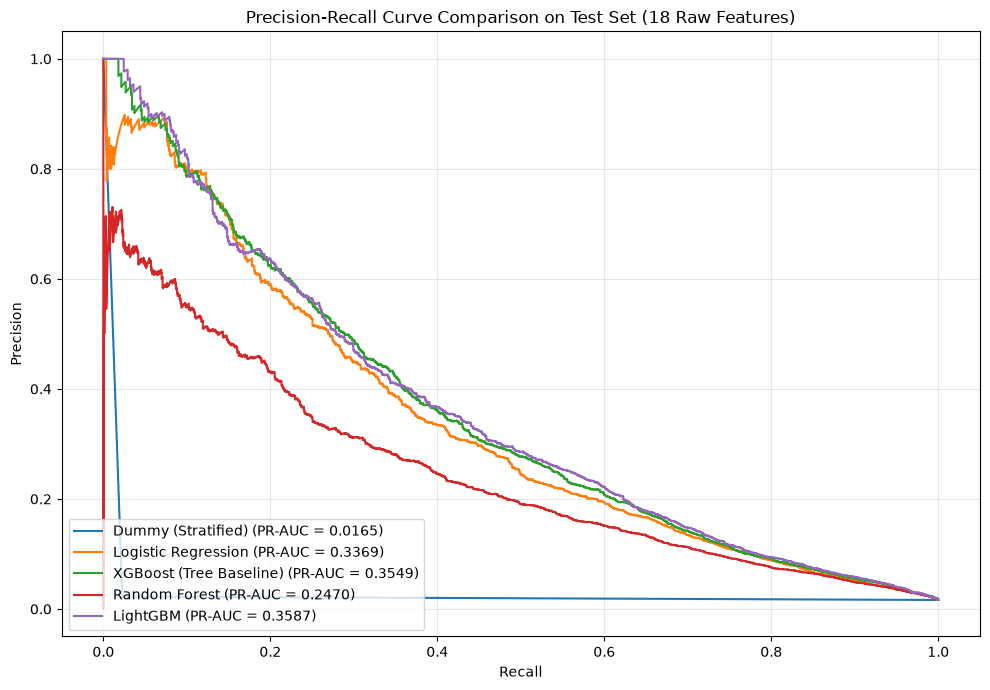

In [11]:
plt.figure(figsize=(10, 7))
for m_name in models_results.keys():
    p, r, _ = precision_recall_curve(y_test, test_probs[m_name])
    plt.plot(r, p, label=f"{m_name} (PR-AUC = {models_results[m_name]['test']['PR-AUC']:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison on Test Set (18 Raw Features)")
plt.legend(loc="lower left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## TASK 6: Feature Importance & Sanity Check Nhanh (Gain-based)

Xuất Gain-based Feature Importance trực tiếp từ mô hình GBM tốt nhất để kiểm tra mức độ ảnh hưởng của từng biến.


In [12]:
if HAS_XGBOOST:
    # Lấy Gain-based Feature Importance chuẩn của XGBoost
    score_dict = best_gbm_model.get_booster().get_score(importance_type="gain")
    total_gain = sum(score_dict.values())
    df_imp = pd.DataFrame([
        {"Feature": k, "Importance_Gain": v, "Normalized_Gain": v / total_gain}
        for k, v in score_dict.items()
    ]).sort_values(by="Importance_Gain", ascending=False).reset_index(drop=True)
else:
    from sklearn.inspection import permutation_importance
    perm_imp = permutation_importance(
        best_gbm_model, X_valid_hgb, y_valid,
        scoring="average_precision",
        n_repeats=3,
        random_state=42,
        n_jobs=1
    )
    sorted_idx = perm_imp.importances_mean.argsort()[::-1]
    df_imp = pd.DataFrame({
        "Feature": [feature_cols[i] for i in sorted_idx],
        "Importance_Gain": perm_imp.importances_mean[sorted_idx],
        "Normalized_Gain": perm_imp.importances_mean[sorted_idx] / perm_imp.importances_mean.sum()
    })

print("Top 10 Feature quan trọng nhất (Gain-based):")
display(df_imp.head(10))


Top 10 Feature quan trọng nhất (Gain-based):


,Feature,Importance_Gain,Normalized_Gain
0,cvv_retry_count,3940.579590,0.463213
1,auth_method,926.753418,0.108939
2,merchant_risk_score,912.586060,0.107274
3,velocity_score,609.238159,0.071616
4,customer_age,317.624908,0.037337
5,prior_disputes,227.079102,0.026693
6,merchant_category,191.577286,0.022520
7,txn_count_last_24h,181.840240,0.021375
8,hours_since_last_txn,141.749695,0.016663
9,amount_usd,127.710503,0.015012


---
## Lưu trữ Artifacts (Model, Preprocessor, Metrics)


In [13]:
os.makedirs(PROJECT_ROOT / "data/artifacts", exist_ok=True)

joblib.dump(best_gbm_model, PROJECT_ROOT / "data/artifacts/best_gbm_baseline.joblib")
joblib.dump(preprocessor_B, PROJECT_ROOT / "data/artifacts/preprocessor_pipeline_b.joblib")
df_summary.to_csv(PROJECT_ROOT / "data/artifacts/baseline_metrics_summary.csv", index=False)
df_imp.to_csv(PROJECT_ROOT / "data/artifacts/baseline_feature_importance.csv", index=False)

print("Đã lưu toàn bộ artifacts thành công vào data/artifacts/!")


Đã lưu toàn bộ artifacts thành công vào data/artifacts/!
